# Milestone 5: whole-furnace 1D model vs REDUCTOR, case A

Reference: Marsigny, Mirgaux & Patisson (2025), *Operating Solutions to Improve the Direct
Reduction of Iron Ore by Hydrogen in a Shaft Furnace*, Metals 15:862 (CC BY 4.0). REDUCTOR is a
2D axisymmetric model of the whole furnace (15 m cylinder + 10 m cone).

- Inputs: `data/furnace.yaml` (quotes checked by `tests/test_provenance.py`).
- Outputs: Table 1, `tests/data/reference_model_marsigny2025b_caseA.csv`
  (`scripts/extract_reductor_table1.py`).
- Profiles: cross-section averages of the case A maps (Figs. 3, 4, 6-9),
  `tests/data/reference_model_marsigny2025b_caseA_profiles.csv`
  (`scripts/digitize_reductor_maps.py`). Each value is known only to within its colour band
  (±50 K, ±0.025 in H₂ fraction, ±0.05 in mass fraction).

No model parameter was adjusted to this case. The kinetics come from the same group (Marsigny
et al. 2025, Metals 15:1034, refitted in Milestone 2), so this compares furnace models, not
independent chemistry. Full discussion: `docs/validation.md`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import compare_reductor as cr
import pandas as pd

N_CELLS = 400  # about 15 min; the grid study is in docs/validation.md
prob, sol = cr.run(N_CELLS)
print(
    f"converged: {sol.converged}, outer iterations: {sol.outer_iterations}, "
    f"energy closure: {sol.energy_closure:.1e}"
)

converged: True, outer iterations: 36, energy closure: 1.5e-16


## Outlet quantities (Table 1)

Difference = model − REDUCTOR, in the units of Table 1.

In [2]:
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
cr.output_table(prob, sol)

,key,REDUCTOR,model,difference,relative
0,top_gas_flow,2796,2800,4,0.001431
1,top_gas_T,344,360.3,16.32,0.04744
2,top_gas_x_H2,64.1,65.54,1.445,0.02254
3,top_gas_x_H2O,30.9,29.46,-1.445,-0.04675
4,top_gas_x_N2,5,5,4.441e-15,8.882e-16
5,dri_flow,117.2,117.7,0.5316,0.004537
6,dri_T,261,298.3,37.35,0.1431
7,dri_w_Fe2O3,0,0,0,NaN
8,dri_w_Fe3O4,0.5,0,-0.5,-1
9,dri_w_FeO,7.71,10.2,2.494,0.3234


## Axial profiles

Shaded: range of the REDUCTOR cross-section average allowed by the colour bands; line: band midpoints. Diamonds: Table 1 DRI values at the solid outlet (z = −10 m).

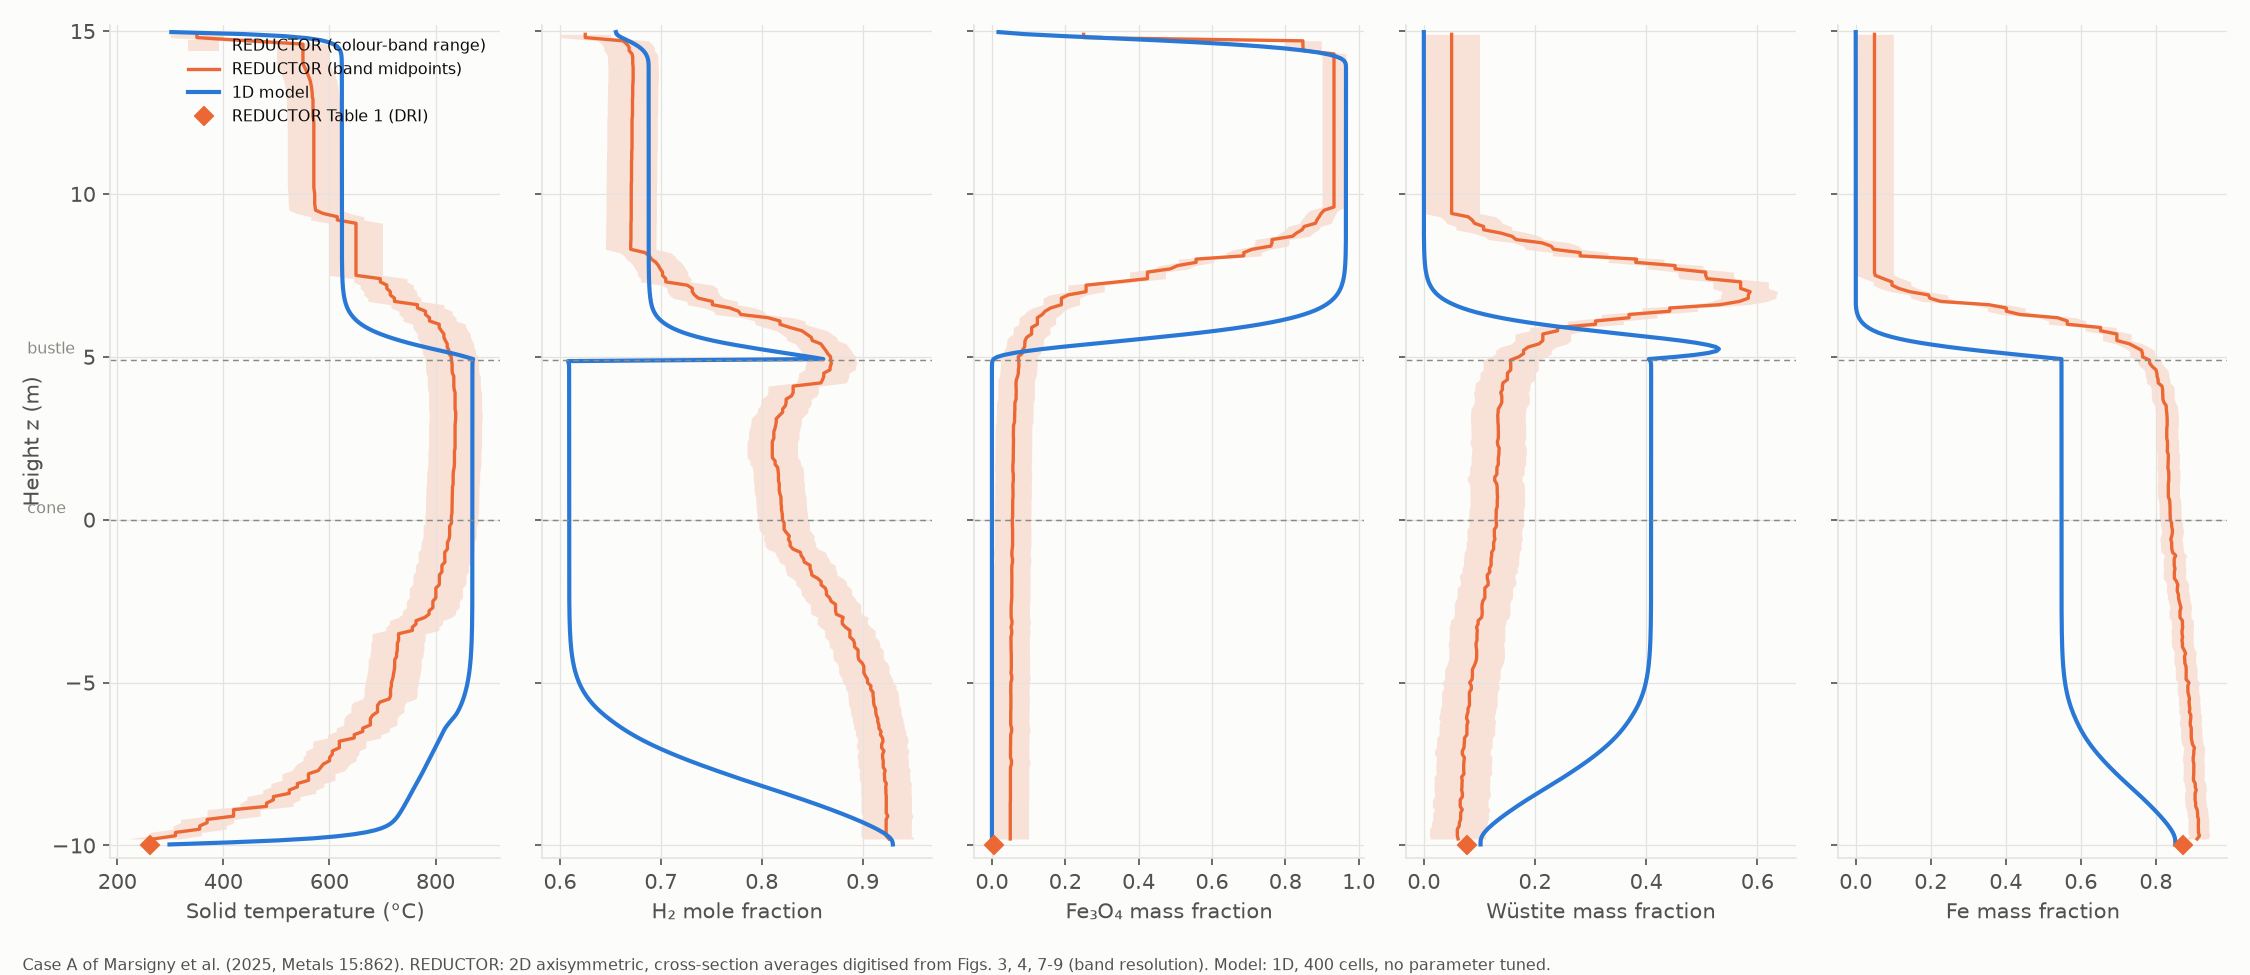

In [3]:
from IPython.display import Image

out = cr.plot(prob, sol)
Image(filename=str(out))

## Profile agreement

`within_band`: fraction of the 0.1 m points where the model lies inside the band; `mean_excess` / `max_excess`: distance of the model outside the band (0 inside); `rms_midpoint`: RMS difference to the band midpoints.

In [4]:
cr.profile_table(prob, sol)

,region,quantity,n_points,within_band,mean_excess,max_excess,rms_midpoint
0,whole furnace,T_solid,248,0.3387,47.61,308.6,118.7
1,above bustle,T_solid,101,0.2574,18.47,145.5,71.71
2,below bustle,T_solid,148,0.3986,67.18,308.6,141.8
3,whole furnace,x_H2,248,0.3306,0.1176,0.2629,0.1752
4,above bustle,x_H2,101,0.7525,0.01314,0.1084,0.04425
5,below bustle,x_H2,148,0.04054,0.1889,0.2629,0.2241
6,whole furnace,w_Fe2O3,248,0.1129,0.0035,0.1868,0.05542
7,above bustle,w_Fe2O3,101,0.0396,0.005963,0.1868,0.06028
8,below bustle,w_Fe2O3,148,0.1622,0.001807,0.003841,0.05182
9,whole furnace,w_Fe3O4,248,0.121,0.06928,0.6936,0.207


## Where and why the models differ

1. **Outlet values agree within a few percent; the axial path does not.** Metallisation is
   1.7 points lower (91.6 vs 93.3 %; the grid study puts the converged value near 90-91 %),
   the DRI leaves 37 K hotter, the top gas 16 K hotter, GUD 0.31 vs 0.33.
2. **Upper shaft:** both models show the low-temperature plateau where magnetite waits (model
   about 620 °C, REDUCTOR 500-650 °C), and hematite disappears at the top in both. The model's
   magnetite/wüstite front lies about 1.5-2 m lower. In REDUCTOR the bustle gas enters at the
   wall at 890 °C, and the outer annulus, which carries most of the cross-section, is reduced
   above the bustle (Fig. 9), while a narrow, H₂-starved core stays wüstite down to the outlet
   (the paper notes this). A 1D model spreads the bustle gas over the whole cross-section, and
   the burden reaches the bustle less reduced (Fe mass fraction about 0.55 vs 0.8).
3. **Below the bustle the regimes differ.** In 1D only the 500 mol/s of cooling gas flows
   there; it meets a burden still holding about 40 % wüstite and reaches the Fe/wüstite
   equilibrium (x_H₂ about 0.61), so reduction stops until the bottom of the cone, where the
   gas is fresh and cold. In REDUCTOR the burden arrives mostly reduced and the cooling gas
   stays H₂-rich (x_H₂ 0.83-0.9).
4. **Cooling zone:** the cooling gas has a much smaller heat-capacity flow than the burden. In
   1D it is heated to the burden temperature within the last metre, so the burden stays near
   870 °C down to z = -6 m and is cooled in a thin front at the outlet; REDUCTOR cools the
   burden gradually through the whole cone. The thin front is also why the 1D results converge
   slowly with the grid (coarse grids smear it).
5. **The outlet agreement is therefore partly compensation** (different paths, similar end
   points) and must not be read as a validation of the 1D path.

These are interpretations of the comparison, not tested hypotheses; a radial (2D) model would
be needed to test them.

## Grid study to 3200 cells (Milestone 8)

With the coupled solver (`shaftsim.coupled`), each grid started from the previous one, case A runs on 3200 cells in about 2 minutes (`python scripts/run_grid_study.py`, results in `results/cases/grid_caseA.json`). Between 400 and 3200 cells the differences halve with each refinement (first order), so the extrapolated values below are the converged estimates used in `docs/validation.md`.

In [5]:
import json

import run_grid_study as rg
from IPython.display import display

grid = json.loads((ROOT / "results" / "cases" / "grid_caseA.json").read_text())
cols = ["cells", "converged", "seconds", "metallization", "dri_T_C", "top_gas_T_C", "gud"]
gtab = pd.DataFrame(grid)[cols]
display(gtab.round({"seconds": 0, "metallization": 4, "dri_T_C": 1, "top_gas_T_C": 1, "gud": 4}))
for k in ("metallization", "dri_T_C", "top_gas_T_C", "gud"):
    ext, order = rg.richardson(grid, k)
    print(f"{k}: extrapolated {ext:.4g} (observed order {order:.2f})")

,cells,converged,seconds,metallization,dri_T_C,top_gas_T_C,gud
0,50,True,68,0.9456,268.3,363,0.3165
1,100,True,48,0.9367,278.8,361.9,0.3146
2,200,True,50,0.9237,291,360.9,0.3118
3,400,True,58,0.9157,298.3,360.3,0.3101
4,800,True,59,0.9112,302.5,360,0.3091
5,1600,True,121,0.9088,304.7,359.8,0.3086
6,3200,True,140,0.9075,305.8,359.7,0.3083


metallization: extrapolated 0.9062 (observed order 0.96)
dri_T_C: extrapolated 306.9 (observed order 0.97)
top_gas_T_C: extrapolated 359.6 (observed order 0.96)
gud: extrapolated 0.308 (observed order 0.96)
